# Random Forest

## ¿Cuál es el objetivo de Random Forest?

**Random Forest** es un algoritmo de **clasificación** (y regresión) que construye **múltiples árboles de decisión** y combina sus predicciones mediante **voto por mayoría**. Es un método de **ensemble** (ensamble): en lugar de confiar en un solo modelo, entrena muchos modelos y agrega sus resultados.

La idea es simple pero poderosa: un solo árbol de decisión puede sobreajustar fácilmente a los datos. Pero si entrenamos **muchos árboles diferentes** y los hacemos votar, los errores individuales tienden a **cancelarse** entre sí.

$$
\hat{y} = \text{moda}\{T_1(\mathbf{x}), \ T_2(\mathbf{x}), \ \dots, \ T_B(\mathbf{x})\}
$$

Donde:

- $T_b(\mathbf{x})$: predicción del árbol $b$ para el punto $\mathbf{x}$.
- $B$: número total de árboles (n_trees).
- moda: la clase más votada.

Para que los árboles sean **diferentes entre sí**, Random Forest introduce dos fuentes de aleatoriedad:

1. **Bootstrap sampling**: cada árbol se entrena con una muestra aleatoria **con reemplazo** del dataset original.
2. **Feature subsampling**: en cada split, cada árbol solo considera un **subconjunto aleatorio** de features.

Esta combinación de **Bagging** (Bootstrap AGGregatING) + feature subsampling reduce la **varianza** del modelo sin aumentar significativamente el **sesgo**.

**Ventajas clave:**
- Mucho más **robusto** que un solo árbol (menos sobreajuste).
- Funciona bien "out of the box" con pocos hiperparámetros que ajustar.
- Maneja bien datasets grandes con muchas features.
- Es uno de los algoritmos más utilizados en la práctica.

**Supongamos un ejemplo intuitivo**

Imagina que quieres decidir si una película será buena. Podrías:

- **Opción A (1 árbol):** Preguntar a un solo crítico. Puede tener sesgos o gustos particulares.
- **Opción B (Random Forest):** Preguntar a 100 críticos, donde cada uno vio la película con diferentes expectativas (bootstrap) y se enfocó en diferentes aspectos (feature subsampling). La opinión mayoritaria será mucho más confiable.

Ahora con datos reales. Usemos el mismo tipo de datos que en el notebook de Decision Tree:

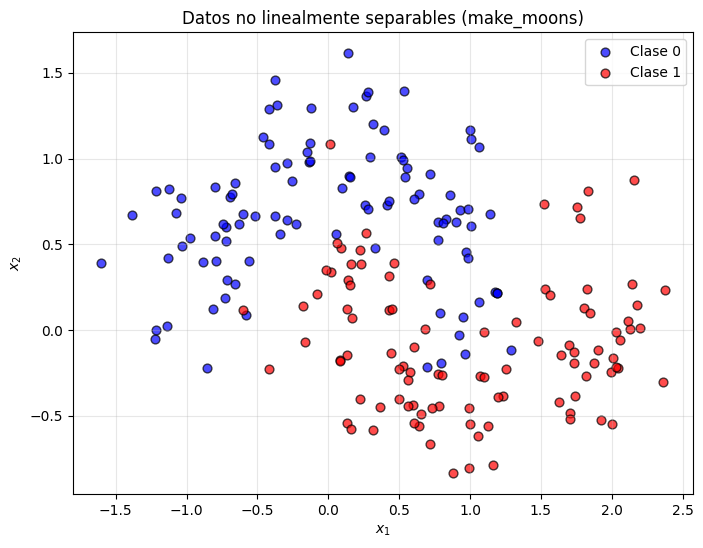

Estos datos son difíciles: ni una línea ni un solo split los separan bien.
Un solo árbol puede sobreajustar. Random Forest combinará muchos árboles.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

np.random.seed(42)

# Generar datos de ejemplo
from sklearn.datasets import make_moons
X, y = make_moons(n_samples=200, noise=0.25, random_state=42)

plt.figure(figsize=(8, 6))
plt.scatter(X[y == 0, 0], X[y == 0, 1], color='blue', s=40, label='Clase 0', edgecolors='black', alpha=0.7)
plt.scatter(X[y == 1, 0], X[y == 1, 1], color='red', s=40, label='Clase 1', edgecolors='black', alpha=0.7)
plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.title('Datos no linealmente separables (make_moons)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

print(f"Estos datos son difíciles: ni una línea ni un solo split los separan bien.")
print(f"Un solo árbol puede sobreajustar. Random Forest combinará muchos árboles.")

## ¿Cómo funciona Random Forest?

Random Forest combina dos ideas fundamentales:

1. **Bagging**: entrenar cada árbol con un dataset diferente (muestra bootstrap).
2. **Feature subsampling**: en cada split, limitar las features candidatas.

Juntas, estas técnicas hacen que los árboles sean **diversos**: cometan errores diferentes. Y cuando errores diferentes se promedian, el resultado es más preciso que cualquier modelo individual.

Esto se conoce como la **"sabiduría de las multitudes"** en Machine Learning.

## Demostración Matemática

### Paso 1: Bootstrap Sampling

Dado un dataset de $n$ muestras, una **muestra bootstrap** se crea tomando $n$ muestras **con reemplazo** del dataset original:

$$
D_b = \{(\mathbf{x}_{i_1}, y_{i_1}), (\mathbf{x}_{i_2}, y_{i_2}), \dots, (\mathbf{x}_{i_n}, y_{i_n})\} \quad \text{donde } i_k \sim \text{Uniforme}\{1, \dots, n\}
$$

Como el muestreo es **con reemplazo**, algunas muestras aparecerán varias veces y otras no aparecerán.

**¿Qué proporción del dataset original aparece en cada muestra bootstrap?**

La probabilidad de que una muestra específica **no** sea elegida en ninguno de los $n$ sorteos es:

$$
P(\text{no elegida}) = \left(1 - \frac{1}{n}\right)^n \xrightarrow{n \to \infty} \frac{1}{e} \approx 0.368
$$

Esto significa que cada muestra bootstrap contiene aproximadamente el **63.2%** del dataset original. El 36.8% restante se llama **out-of-bag (OOB)** y puede usarse para estimar el error de generalización sin necesidad de un conjunto de validación.

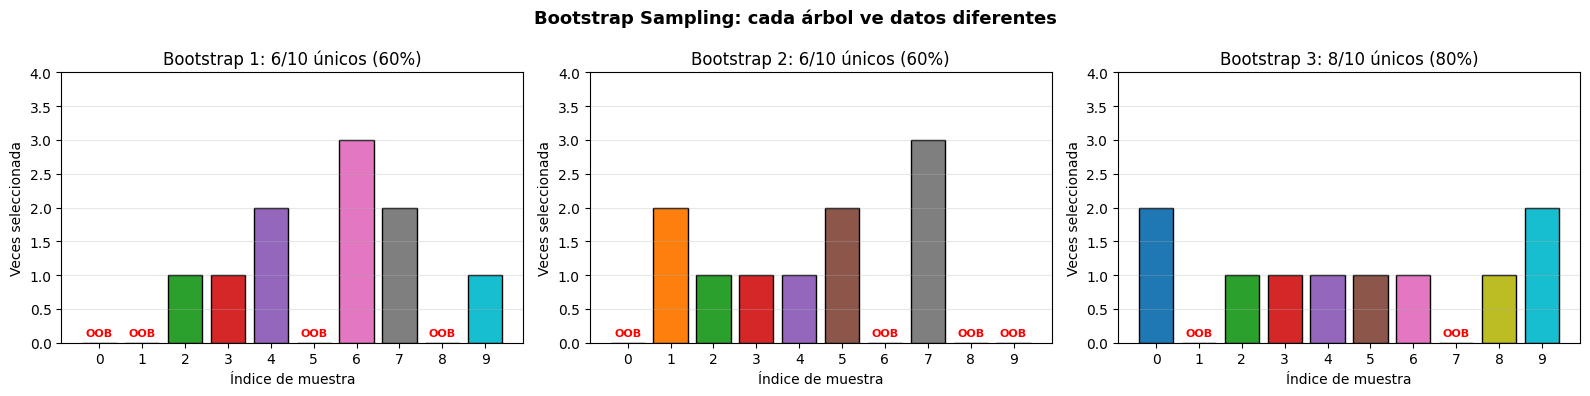

Proporción promedio de muestras únicas: 0.6321 (teórico: 0.6321)


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

np.random.seed(42)

import warnings
warnings.filterwarnings("ignore", category=SyntaxWarning)

# Demostrar bootstrap sampling
n = 10
original = np.arange(n)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
colors_original = plt.cm.tab10(np.linspace(0, 1, n))

for i, ax in enumerate(axes):
    bootstrap_idxs = np.random.choice(n, n, replace=True)
    unique_selected = len(np.unique(bootstrap_idxs))

    # Contar ocurrencias
    counts = np.bincount(bootstrap_idxs, minlength=n)

    bars = ax.bar(range(n), counts, color=colors_original, edgecolor='black')
    ax.set_xlabel('Índice de muestra')
    ax.set_ylabel('Veces seleccionada')
    ax.set_title(f'Bootstrap {i+1}: {unique_selected}/{n} únicos ({unique_selected/n*100:.0f}%)')
    ax.set_xticks(range(n))
    ax.set_ylim(0, 4)
    ax.grid(True, alpha=0.3, axis='y')

    # Marcar los no seleccionados
    for j, c in enumerate(counts):
        if c == 0:
            ax.text(j, 0.1, 'OOB', ha='center', fontsize=8, color='red', fontweight='bold')

plt.suptitle('Bootstrap Sampling: cada árbol ve datos diferentes', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Verificar el 63.2% empíricamente
n_large = 10000
proportions = []
for _ in range(1000):
    idxs = np.random.choice(n_large, n_large, replace=True)
    proportions.append(len(np.unique(idxs)) / n_large)
print(f"Proporción promedio de muestras únicas: {np.mean(proportions):.4f} (teórico: {1 - 1/np.e:.4f})")

### Paso 2: Feature Subsampling

En un árbol de decisión normal, al buscar el mejor split, se evalúan **todas** las $d$ features. En Random Forest, cada split solo evalúa un **subconjunto aleatorio** de $m$ features:

$$
m \ll d
$$

Reglas prácticas para elegir $m$:

- **Clasificación**: $m = \lfloor\sqrt{d}\rfloor$ (raíz cuadrada del total de features).
- **Regresión**: $m = \lfloor d/3 \rfloor$ (un tercio del total).

**¿Por qué limitar las features?**

Si una feature es muy buena, **todos los árboles** la usarían en los primeros splits, haciendo que los árboles sean muy **similares** (correlacionados). Al forzar subconjuntos aleatorios:

- Algunos árboles no tendrán acceso a la "mejor" feature.
- Se verán obligados a usar **otras features**, descubriendo patrones diferentes.
- Los árboles se vuelven más **diversos**, que es exactamente lo que necesitamos.

### Paso 3: Agregación por voto mayoritario

Una vez entrenados los $B$ árboles, para predecir la clase de un nuevo punto $\mathbf{x}$:

1. Cada árbol $T_b$ emite su voto: $T_b(\mathbf{x}) \in \{c_1, c_2, \dots, c_C\}$
2. La predicción final es la **clase más votada** (moda):

$$
\hat{y} = \text{moda}\{T_1(\mathbf{x}), T_2(\mathbf{x}), \dots, T_B(\mathbf{x})\}
$$

**¿Por qué funciona la agregación?**

Consideremos un caso simplificado: tenemos $B$ clasificadores binarios independientes, cada uno con accuracy $p > 0.5$. La probabilidad de que la **mayoría** acierte (por el teorema del jurado de Condorcet) es:

$$
P(\text{mayoría acierta}) = \sum_{k=\lceil B/2 \rceil}^{B} \binom{B}{k} p^k (1-p)^{B-k}
$$

Cuando $B \to \infty$, esta probabilidad tiende a **1** (siempre que $p > 0.5$). En la práctica, con suficientes árboles diversos, el ensemble es significativamente mejor que cualquier árbol individual.

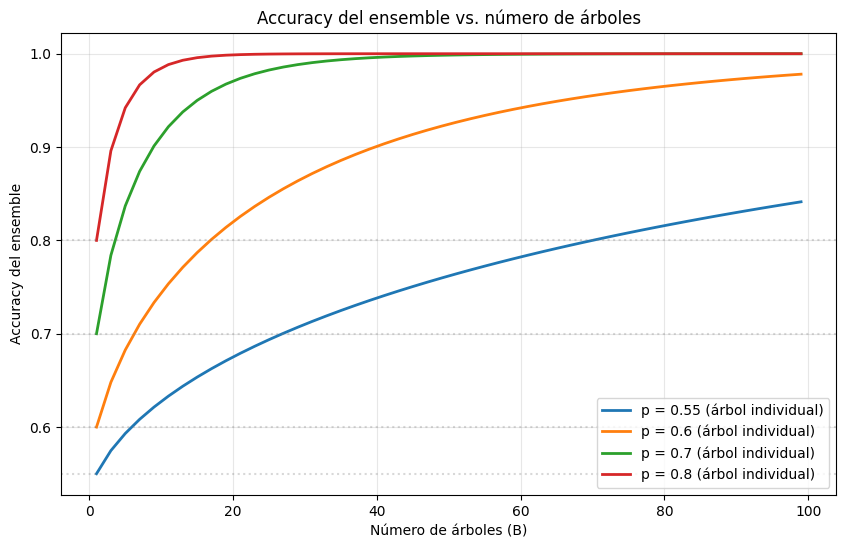

Con árboles que individualmente aciertan >50%, el ensemble mejora al agregar más árboles.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import binom

# Visualizar cómo la accuracy del ensemble mejora con más árboles
B_range = range(1, 101, 2)
p_values = [0.55, 0.6, 0.7, 0.8]

plt.figure(figsize=(10, 6))
for p in p_values:
    ensemble_acc = []
    for B in B_range:
        # P(mayoría acierta)
        majority = B // 2 + 1
        prob = 1 - binom.cdf(majority - 1, B, p)
        ensemble_acc.append(prob)
    plt.plot(B_range, ensemble_acc, linewidth=2, label=f'p = {p} (árbol individual)')
    plt.axhline(y=p, linestyle=':', alpha=0.3, color='gray')

plt.xlabel('Número de árboles (B)')
plt.ylabel('Accuracy del ensemble')
plt.title('Accuracy del ensemble vs. número de árboles')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

print("Con árboles que individualmente aciertan >50%, el ensemble mejora al agregar más árboles.")

### ¿Por qué Random Forest reduce el sobreajuste?

Un solo árbol profundo tiene **alta varianza**: pequeños cambios en los datos producen árboles muy diferentes. Random Forest reduce esto mediante el promedio:

Si cada árbol tiene varianza $\sigma^2$ y la **correlación** entre árboles es $\rho$, la varianza del promedio de $B$ árboles es:

$$
\text{Var}_{\text{ensemble}} = \rho \cdot \sigma^2 + \frac{1 - \rho}{B} \cdot \sigma^2
$$

Dos observaciones clave:

1. El segundo término **decrece** con $B$ → más árboles = menos varianza.
2. El primer término depende de $\rho$ → árboles menos correlacionados (más diversos) = menos varianza.

El **feature subsampling** reduce $\rho$, y el **bootstrap** introduce diversidad adicional. Juntos, hacen que Random Forest sea uno de los algoritmos más robustos.

### Resumen del algoritmo

**Entrenamiento:**

Para $b = 1, 2, \dots, B$:
1. Crear una muestra bootstrap $D_b$ del dataset original (muestreo con reemplazo).
2. Entrenar un árbol de decisión $T_b$ sobre $D_b$, con la modificación de que en cada split solo se consideran $m$ features aleatorias.

**Predicción:**

$$
\hat{y} = \text{moda}\{T_1(\mathbf{x}), T_2(\mathbf{x}), \dots, T_B(\mathbf{x})\}
$$

**Hiperparámetros:**

| Hiperparámetro | Descripción | Valor típico |
|----------------|-------------|-------------|
| `n_trees` ($B$) | Número de árboles | 100 - 500 |
| `max_depth` | Profundidad máxima de cada árbol | Sin límite o 10-30 |
| `n_feats` ($m$) | Features por split | $\sqrt{d}$ |
| `min_samples_split` | Mínimo para dividir un nodo | 2 |

### Ejemplo numérico

Veamos cómo funciona la votación con un ejemplo simple. Tenemos 5 árboles y queremos clasificar un punto $\mathbf{x}$:

| Árbol | Muestra bootstrap | Features en split | Predicción |
|-------|-------------------|-------------------|------------|
| $T_1$ | {1,1,3,4,5,6,7,8} | {temp, humedad} | Clase 1 |
| $T_2$ | {1,2,2,4,5,5,7,8} | {humedad}       | Clase 0 |
| $T_3$ | {1,3,3,4,6,6,7,8} | {temp}          | Clase 1 |
| $T_4$ | {2,2,3,5,5,6,7,8} | {temp, humedad} | Clase 1 |
| $T_5$ | {1,2,4,4,5,6,7,7} | {humedad}       | Clase 0 |

**Votación:**
- Clase 0: **2 votos** ($T_2$, $T_5$)
- Clase 1: **3 votos** ($T_1$, $T_3$, $T_4$)

$$
\boxed{\hat{y} = \text{Clase 1} \quad \text{(3 votos vs 2)}}
$$

Notar que cada árbol vio datos diferentes y consideró features diferentes. Aun así, la mayoría acertó.

In [ ]:
import numpy as np
from collections import Counter

np.random.seed(42)

# Simulación de votación
n_trees = 5
# Supongamos que cada árbol tiene 70% de accuracy individual
true_class = 1

print("=== Ejemplo numérico: Votación en Random Forest ===")
print(f"Clase real: {true_class}")
print(f"Cada árbol tiene ~70% de accuracy individual\n")

# Simular muchas predicciones
n_simulations = 10000
individual_correct = 0
ensemble_correct = 0

for _ in range(n_simulations):
    # Cada árbol predice correctamente con prob 0.7
    predictions = np.random.choice([0, 1], size=n_trees, p=[0.3, 0.7])

    # Accuracy individual (primer árbol)
    if predictions[0] == true_class:
        individual_correct += 1

    # Accuracy ensemble (voto mayoritario)
    majority_vote = Counter(predictions).most_common(1)[0][0]
    if majority_vote == true_class:
        ensemble_correct += 1

print(f"Accuracy individual (1 árbol):     {individual_correct/n_simulations:.4f}")
print(f"Accuracy ensemble ({n_trees} árboles):    {ensemble_correct/n_simulations:.4f}")
print(f"\nMejora: +{(ensemble_correct - individual_correct)/n_simulations * 100:.1f} puntos porcentuales")

=== Ejemplo numérico: Votación en Random Forest ===
Clase real: 1
Cada árbol tiene ~70% de accuracy individual

Accuracy individual (1 árbol):     0.7005
Accuracy ensemble (5 árboles):    0.8340

Mejora: +13.4 puntos porcentuales


## Implementación con Código

### Funciones

In [ ]:
from collections import Counter
import numpy as np


# === Decision Tree (necesario para Random Forest) ===

def entropy(y):
    hist = np.bincount(y)
    ps = hist / len(y)
    return -np.sum([p * np.log2(p) for p in ps if p > 0])


class Node:
    def __init__(self, feature=None, threshold=None, left=None, right=None, *, value=None):
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right
        self.value = value

    def is_leaf_node(self):
        return self.value is not None


class DecisionTree:
    def __init__(self, min_samples_split=2, max_depth=100, n_feats=None):
        self.min_samples_split = min_samples_split
        self.max_depth = max_depth
        self.n_feats = n_feats
        self.root = None

    def fit(self, X, y):
        self.n_feats = X.shape[1] if not self.n_feats else min(self.n_feats, X.shape[1])
        self.root = self._grow_tree(X, y)

    def predict(self, X):
        return np.array([self._traverse_tree(x, self.root) for x in X])

    def _grow_tree(self, X, y, depth=0):
        n_samples, n_features = X.shape
        n_labels = len(np.unique(y))

        if depth >= self.max_depth or n_labels == 1 or n_samples < self.min_samples_split:
            return Node(value=self._most_common_label(y))

        feat_idxs = np.random.choice(n_features, self.n_feats, replace=False)
        best_feat, best_thresh = self._best_criteria(X, y, feat_idxs)

        left_idxs, right_idxs = self._split(X[:, best_feat], best_thresh)
        left = self._grow_tree(X[left_idxs, :], y[left_idxs], depth + 1)
        right = self._grow_tree(X[right_idxs, :], y[right_idxs], depth + 1)
        return Node(best_feat, best_thresh, left, right)

    def _best_criteria(self, X, y, feat_idxs):
        best_gain = -1
        split_idx, split_thresh = None, None
        for feat_idx in feat_idxs:
            X_column = X[:, feat_idx]
            thresholds = np.unique(X_column)
            for threshold in thresholds:
                gain = self._information_gain(y, X_column, threshold)
                if gain > best_gain:
                    best_gain = gain
                    split_idx = feat_idx
                    split_thresh = threshold
        return split_idx, split_thresh

    def _information_gain(self, y, X_column, split_thresh):
        parent_entropy = entropy(y)
        left_idxs, right_idxs = self._split(X_column, split_thresh)
        if len(left_idxs) == 0 or len(right_idxs) == 0:
            return 0
        n = len(y)
        n_l, n_r = len(left_idxs), len(right_idxs)
        e_l, e_r = entropy(y[left_idxs]), entropy(y[right_idxs])
        child_entropy = (n_l / n) * e_l + (n_r / n) * e_r
        return parent_entropy - child_entropy

    def _split(self, X_column, split_thresh):
        left_idxs = np.argwhere(X_column <= split_thresh).flatten()
        right_idxs = np.argwhere(X_column > split_thresh).flatten()
        return left_idxs, right_idxs

    def _traverse_tree(self, x, node):
        if node.is_leaf_node():
            return node.value
        if x[node.feature] <= node.threshold:
            return self._traverse_tree(x, node.left)
        return self._traverse_tree(x, node.right)

    def _most_common_label(self, y):
        counter = Counter(y)
        return counter.most_common(1)[0][0]


# === Random Forest (funciones) ===

def bootstrap_sample(X, y):
    """Crea una muestra bootstrap (con reemplazo)"""
    n_samples = X.shape[0]
    idxs = np.random.choice(n_samples, n_samples, replace=True)
    return X[idxs], y[idxs]

def most_common_label(y):
    """Retorna la clase más frecuente"""
    counter = Counter(y)
    return counter.most_common(1)[0][0]

def random_forest_fit(X, y, n_trees=10, max_depth=100, n_feats=None):
    """Entrena un Random Forest"""
    trees = []
    for _ in range(n_trees):
        tree = DecisionTree(max_depth=max_depth, n_feats=n_feats)
        X_samp, y_samp = bootstrap_sample(X, y)
        tree.fit(X_samp, y_samp)
        trees.append(tree)
    return trees

def random_forest_predict(X, trees):
    """Predice usando voto mayoritario"""
    tree_preds = np.array([tree.predict(X) for tree in trees])
    tree_preds = np.swapaxes(tree_preds, 0, 1)
    y_pred = [most_common_label(tree_pred) for tree_pred in tree_preds]
    return np.array(y_pred)

In [ ]:
from sklearn import datasets
from sklearn.model_selection import train_test_split

# Cargar datos
data = datasets.load_breast_cancer()
X, y = data.data, data.target

# Dividir
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1234
)

# Entrenar
trees = random_forest_fit(X_train, y_train, n_trees=10, max_depth=10)

# Predecir y evaluar
predictions = random_forest_predict(X_test, trees)
accuracy = np.sum(y_test == predictions) / len(y_test)
print(f"Random Forest accuracy (10 árboles): {accuracy:.4f}")

# Comparar con un solo árbol
single_tree = DecisionTree(max_depth=10)
single_tree.fit(X_train, y_train)
single_pred = single_tree.predict(X_test)
single_acc = np.sum(y_test == single_pred) / len(y_test)
print(f"Decision Tree accuracy (1 árbol):    {single_acc:.4f}")
print(f"Mejora: +{(accuracy - single_acc) * 100:.1f} puntos porcentuales")

Random Forest accuracy (10 árboles): 0.9035
Decision Tree accuracy (1 árbol):    0.9386
Mejora: +-3.5 puntos porcentuales


### Clase

In [ ]:
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap


# === Decision Tree ===

def entropy(y):
    hist = np.bincount(y)
    ps = hist / len(y)
    return -np.sum([p * np.log2(p) for p in ps if p > 0])


class Node:
    def __init__(self, feature=None, threshold=None, left=None, right=None, *, value=None):
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right
        self.value = value

    def is_leaf_node(self):
        return self.value is not None


class DecisionTree:
    def __init__(self, min_samples_split=2, max_depth=100, n_feats=None):
        self.min_samples_split = min_samples_split
        self.max_depth = max_depth
        self.n_feats = n_feats
        self.root = None

    def fit(self, X, y):
        self.n_feats = X.shape[1] if not self.n_feats else min(self.n_feats, X.shape[1])
        self.root = self._grow_tree(X, y)

    def predict(self, X):
        return np.array([self._traverse_tree(x, self.root) for x in X])

    def _grow_tree(self, X, y, depth=0):
        n_samples, n_features = X.shape
        n_labels = len(np.unique(y))
        if depth >= self.max_depth or n_labels == 1 or n_samples < self.min_samples_split:
            return Node(value=self._most_common_label(y))
        feat_idxs = np.random.choice(n_features, self.n_feats, replace=False)
        best_feat, best_thresh = self._best_criteria(X, y, feat_idxs)
        left_idxs, right_idxs = self._split(X[:, best_feat], best_thresh)
        left = self._grow_tree(X[left_idxs, :], y[left_idxs], depth + 1)
        right = self._grow_tree(X[right_idxs, :], y[right_idxs], depth + 1)
        return Node(best_feat, best_thresh, left, right)

    def _best_criteria(self, X, y, feat_idxs):
        best_gain = -1
        split_idx, split_thresh = None, None
        for feat_idx in feat_idxs:
            X_column = X[:, feat_idx]
            thresholds = np.unique(X_column)
            for threshold in thresholds:
                gain = self._information_gain(y, X_column, threshold)
                if gain > best_gain:
                    best_gain = gain
                    split_idx = feat_idx
                    split_thresh = threshold
        return split_idx, split_thresh

    def _information_gain(self, y, X_column, split_thresh):
        parent_entropy = entropy(y)
        left_idxs, right_idxs = self._split(X_column, split_thresh)
        if len(left_idxs) == 0 or len(right_idxs) == 0:
            return 0
        n = len(y)
        n_l, n_r = len(left_idxs), len(right_idxs)
        e_l, e_r = entropy(y[left_idxs]), entropy(y[right_idxs])
        child_entropy = (n_l / n) * e_l + (n_r / n) * e_r
        return parent_entropy - child_entropy

    def _split(self, X_column, split_thresh):
        left_idxs = np.argwhere(X_column <= split_thresh).flatten()
        right_idxs = np.argwhere(X_column > split_thresh).flatten()
        return left_idxs, right_idxs

    def _traverse_tree(self, x, node):
        if node.is_leaf_node():
            return node.value
        if x[node.feature] <= node.threshold:
            return self._traverse_tree(x, node.left)
        return self._traverse_tree(x, node.right)

    def _most_common_label(self, y):
        if len(y) == 0:
            return 0  # Return default class 0 if y is empty
        counter = Counter(y)
        return counter.most_common(1)[0][0]


# === Random Forest ===

def bootstrap_sample(X, y):
    n_samples = X.shape[0]
    idxs = np.random.choice(n_samples, n_samples, replace=True)
    return X[idxs], y[idxs]

def most_common_label(y):
    if len(y) == 0:
        return 0  # Return default class 0 if y is empty
    counter = Counter(y)
    return counter.most_common(1)[0][0]


class RandomForest:
    def __init__(self, n_trees=10, min_samples_split=2, max_depth=100, n_feats=None):
        self.n_trees = n_trees
        self.min_samples_split = min_samples_split
        self.max_depth = max_depth
        self.n_feats = n_feats
        self.trees = []

    def fit(self, X, y):
        """Entrena n_trees árboles, cada uno con una muestra bootstrap"""
        self.trees = []
        for _ in range(self.n_trees):
            tree = DecisionTree(
                min_samples_split=self.min_samples_split,
                max_depth=self.max_depth,
                n_feats=self.n_feats,
            )
            X_samp, y_samp = bootstrap_sample(X, y)
            tree.fit(X_samp, y_samp)
            self.trees.append(tree)

    def predict(self, X):
        """Predice usando voto mayoritario de todos los árboles"""
        tree_preds = np.array([tree.predict(X) for tree in self.trees])
        tree_preds = np.swapaxes(tree_preds, 0, 1)
        y_pred = [most_common_label(tree_pred) for tree_pred in tree_preds]
        return np.array(y_pred)

    def score(self, X, y):
        """Calcula la accuracy del modelo"""
        predictions = self.predict(X)
        return np.sum(predictions == y) / len(y)

    def plot_decision_boundary(self, X, y, title="Frontera de decisión - Random Forest",
                               feature_indices=(0, 1)):
        """Grafica la frontera de decisión usando dos features"""
        i, j = feature_indices
        X_2d = X[:, [i, j]]

        temp_rf = RandomForest(
            n_trees=self.n_trees,
            min_samples_split=self.min_samples_split,
            max_depth=self.max_depth,
            n_feats=self.n_feats
        )
        temp_rf.fit(X_2d, y)

        h = 0.1
        x_min, x_max = X_2d[:, 0].min() - 1, X_2d[:, 0].max() + 1
        y_min, y_max = X_2d[:, 1].min() - 1, X_2d[:, 1].max() + 1
        xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                             np.arange(y_min, y_max, h))

        Z = temp_rf.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)

        n_classes = len(np.unique(y))
        light_colors = ['#FFAAAA', '#AAFFAA', '#AAAAFF'][:n_classes]
        bold_colors = ['#FF0000', '#00FF00', '#0000FF'][:n_classes]

        plt.figure(figsize=(8, 6))
        plt.contourf(xx, yy, Z, alpha=0.3, cmap=ListedColormap(light_colors))
        plt.scatter(X_2d[:, 0], X_2d[:, 1], c=y, cmap=ListedColormap(bold_colors),
                    edgecolors='k', s=60)
        plt.xlabel(f'Feature {i}')
        plt.ylabel(f'Feature {j}')
        plt.title(f'{title} ({self.n_trees} árboles, depth={self.max_depth})')
        plt.grid(True, alpha=0.3)
        plt.show()

In [ ]:
from sklearn import datasets
from sklearn.model_selection import train_test_split

# Cargar datos
data = datasets.load_breast_cancer()
X, y = data.data, data.target

# Dividir
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1234
)

# Entrenar Random Forest
model = RandomForest(n_trees=10, max_depth=10)
model.fit(X_train, y_train)

# Evaluar
acc = model.score(X_test, y_test)
print(f"Random Forest accuracy: {acc:.4f}")

Random Forest accuracy: 0.9035


Decision Tree vs Random Forest:

  Decision Tree (1 árbol):  accuracy = 0.9298
  Random Forest ( 3 árboles): accuracy = 0.9035
  Random Forest ( 5 árboles): accuracy = 0.9298
  Random Forest (10 árboles): accuracy = 0.9561
  Random Forest (20 árboles): accuracy = 0.9298
  Random Forest (50 árboles): accuracy = 0.9298


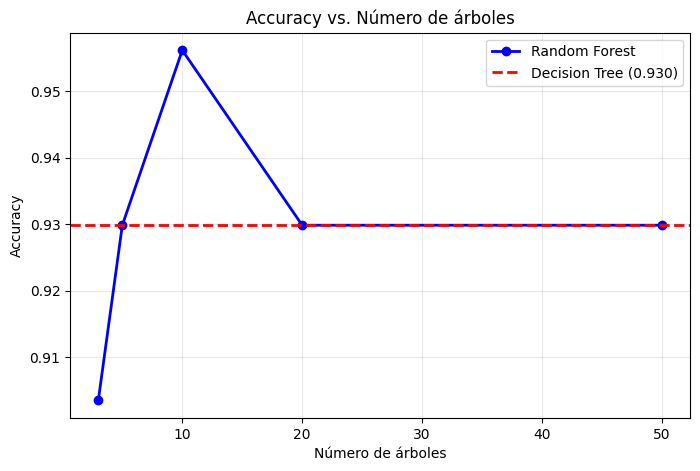

In [ ]:
# Comparar Decision Tree vs Random Forest con diferentes números de árboles
print("Decision Tree vs Random Forest:\n")

# Decision Tree (baseline)
dt = DecisionTree(max_depth=10)
dt.fit(X_train, y_train)
dt_acc = np.sum(y_test == dt.predict(X_test)) / len(y_test)
print(f"  Decision Tree (1 árbol):  accuracy = {dt_acc:.4f}")

# Random Forest con diferentes n_trees
n_trees_list = [3, 5, 10, 20, 50]
rf_accs = []

for n_t in n_trees_list:
    rf = RandomForest(n_trees=n_t, max_depth=10)
    rf.fit(X_train, y_train)
    rf_acc = rf.score(X_test, y_test)
    rf_accs.append(rf_acc)
    print(f"  Random Forest ({n_t:2d} árboles): accuracy = {rf_acc:.4f}")

# Graficar
plt.figure(figsize=(8, 5))
plt.plot(n_trees_list, rf_accs, 'bo-', linewidth=2, label='Random Forest')
plt.axhline(y=dt_acc, color='red', linestyle='--', linewidth=2, label=f'Decision Tree ({dt_acc:.3f})')
plt.xlabel('Número de árboles')
plt.ylabel('Accuracy')
plt.title('Accuracy vs. Número de árboles')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

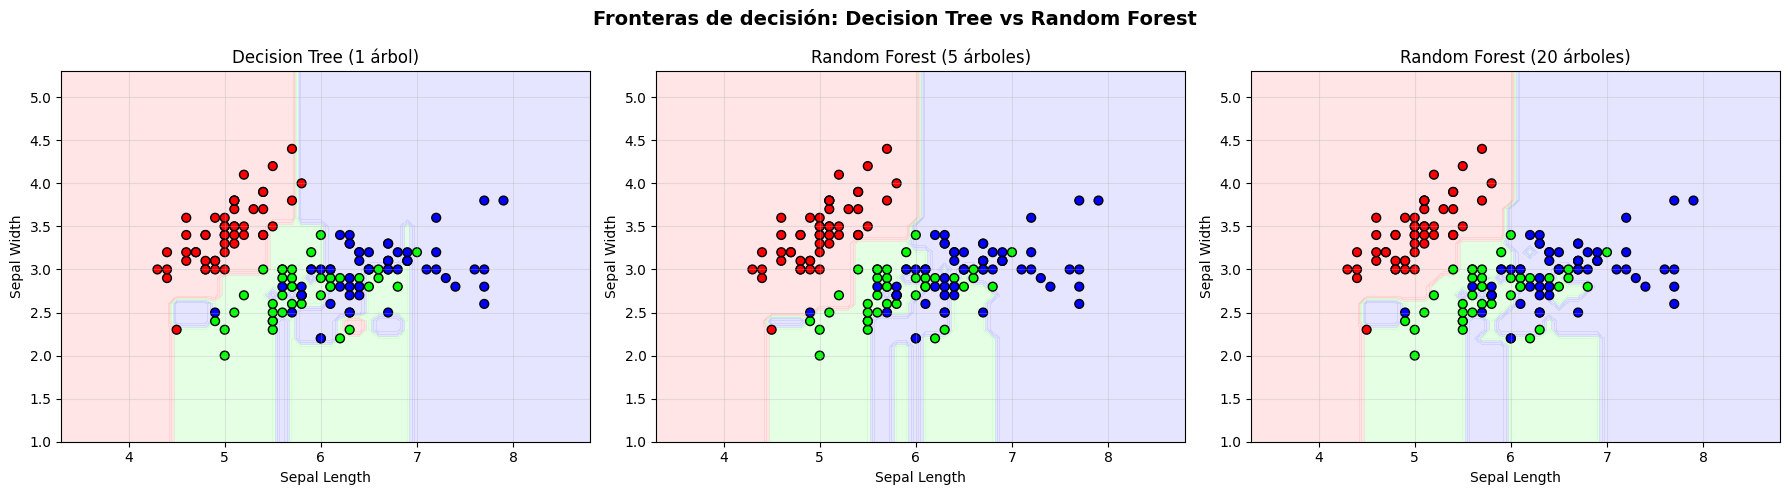

Observar: la frontera de Random Forest es más suave y menos irregular que la de un solo árbol.


In [ ]:
# Comparación visual de fronteras de decisión: 1 árbol vs Random Forest
iris = datasets.load_iris()
X_iris, y_iris = iris.data, iris.target
X_2d = X_iris[:, [0, 1]]  # Solo 2 features para visualizar

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

configs = [
    ("Decision Tree (1 árbol)", 1),
    ("Random Forest (5 árboles)", 5),
    ("Random Forest (20 árboles)", 20),
]

for ax, (title, n_t) in zip(axes, configs):
    if n_t == 1:
        model_vis = DecisionTree(max_depth=10)
        model_vis.fit(X_2d, y_iris)
    else:
        model_vis = RandomForest(n_trees=n_t, max_depth=10)
        model_vis.fit(X_2d, y_iris)

    h = 0.1
    x_min, x_max = X_2d[:, 0].min() - 1, X_2d[:, 0].max() + 1
    y_min, y_max = X_2d[:, 1].min() - 1, X_2d[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

    Z = model_vis.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
    cmap_bold = ListedColormap(['#FF0000', '#00FF00', '#0000FF'])

    ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_light)
    ax.scatter(X_2d[:, 0], X_2d[:, 1], c=y_iris, cmap=cmap_bold, edgecolors='k', s=40)
    ax.set_xlabel('Sepal Length')
    ax.set_ylabel('Sepal Width')
    ax.set_title(title)
    ax.grid(True, alpha=0.3)

plt.suptitle('Fronteras de decisión: Decision Tree vs Random Forest',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("Observar: la frontera de Random Forest es más suave y menos irregular que la de un solo árbol.")